# Introduction to Probability Theory

Probability theory studies the **likelihood of events happening**.
It is foundational for statistics, data science, and risk analysis.

Key concepts:
- **Experiment**: Any process that generates outcomes (e.g., rolling a die).
- **Sample Space ($S$)**: Set of all possible outcomes.
- **Event**: A subset of the sample space.
- **Probability of an event $P(E)$**: A number between 0 and 1 representing the chance the event occurs.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Axioms and Basic Rules

1. $0 \le P(E) \le 1$
2. $P(S) = 1$
3. For mutually exclusive events: $P(E \cup F) = P(E) + P(F)$

Useful consequences:

- **Complement**: $P(E^c) = 1 - P(E)$
- **Addition rule** (general): $P(E \cup F) = P(E) + P(F) - P(E \cap F)$

In [2]:
die <- 1:6
event_even <- c(2, 4, 6)   # rolling an even number
event_gt3  <- c(4, 5, 6)   # rolling a number greater than 3

P <- function(event) length(event) / length(die)

prob_even        <- P(event_even)
prob_gt3         <- P(event_gt3)
prob_even_and_gt3 <- P(intersect(event_even, event_gt3))
prob_even_or_gt3 <- P(union(event_even, event_gt3))

cat("P(even)            =", prob_even, "\n")
cat("P(>3)              =", prob_gt3, "\n")
cat("P(even AND >3)     =", round(prob_even_and_gt3, 4), " {", intersect(event_even, event_gt3), "}\n")
cat("P(even OR >3)      =", round(prob_even_or_gt3, 4), "\n")
cat("Addition rule check:", round(prob_even + prob_gt3 - prob_even_and_gt3, 4), "\n")
cat("P(not even)        =", 1 - prob_even, "\n")

P(even)            = 0.5 


P(>3)              = 0.5 


P(even AND >3)     = 0.3333  { 4 6 }


P(even OR >3)      = 0.6667 


Addition rule check: 0.6667 


P(not even)        = 0.5 


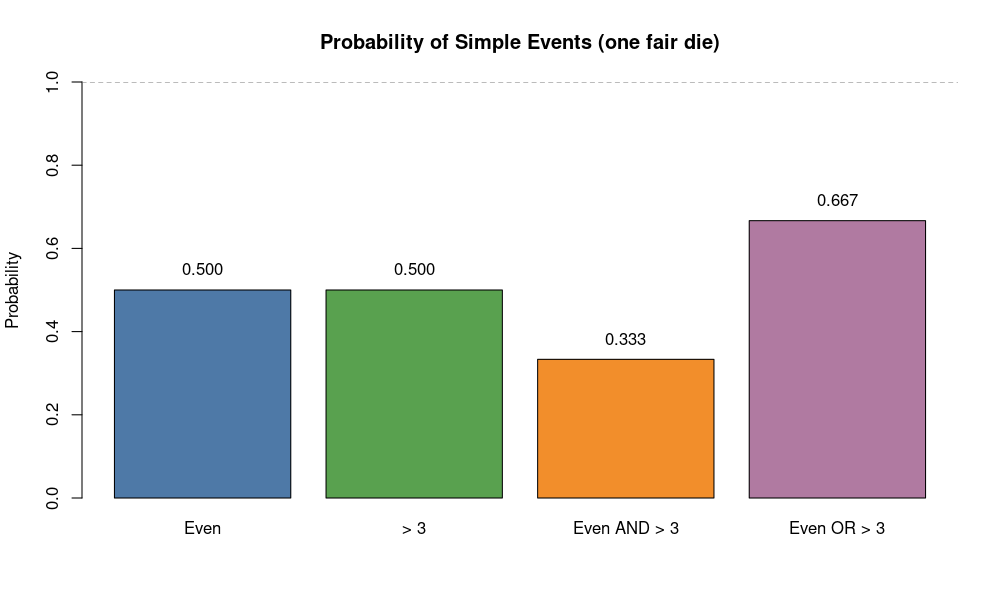

In [3]:
event_names <- c("Even", "> 3", "Even AND > 3", "Even OR > 3")
probs <- c(prob_even, prob_gt3, prob_even_and_gt3, prob_even_or_gt3)

bp <- barplot(probs, names.arg = event_names, col = c("#4E79A7", "#59A14F", "#F28E2B", "#B07AA1"),
              ylim = c(0, 1), main = "Probability of Simple Events (one fair die)", ylab = "Probability")
text(bp, probs + 0.05, sprintf("%.3f", probs))
abline(h = 1, lty = 2, col = "grey50")

## 2. Conditional Probability and Independence

The probability of $A$ **given** that $B$ has happened:

$$
P(A \mid B) = \frac{P(A \cap B)}{P(B)}
$$

Events are **independent** if knowing one tells you nothing about the other: $P(A \mid B) = P(A)$, equivalently $P(A \cap B) = P(A)P(B)$.

In [4]:
p_even_given_gt3 <- prob_even_and_gt3 / prob_gt3
cat("P(even | >3) =", round(p_even_given_gt3, 4), " vs P(even) =", prob_even, "\n")
cat("Independent? ", isTRUE(all.equal(prob_even_and_gt3, prob_even * prob_gt3)), "\n\n")

# Two different dice ARE independent
two_dice <- expand.grid(d1 = 1:6, d2 = 1:6)
pA  <- mean(two_dice$d1 == 6)
pB  <- mean(two_dice$d2 == 6)
pAB <- mean(two_dice$d1 == 6 & two_dice$d2 == 6)
cat("Two dice: P(d1=6)*P(d2=6) =", round(pA * pB, 4), " P(both 6) =", round(pAB, 4), "-> independent\n")

P(even | >3) = 0.6667  vs P(even) = 0.5 


Independent?  FALSE 



Two dice: P(d1=6)*P(d2=6) = 0.0278  P(both 6) = 0.0278 -> independent


## 3. Bayes' Theorem

Bayes' theorem reverses a conditional probability:

$$
P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}, \qquad P(B) = P(B\mid A)P(A) + P(B \mid A^c)P(A^c)
$$

**Classic example — medical testing.** A disease affects 1% of people. A test detects it 95% of the time (sensitivity) and has a 5% false-positive rate. If you test positive, what is the chance you actually have the disease?

P(test positive)          = 0.059 


P(disease | test positive) = 0.161 



Simulated P(disease | positive) = 0.1617 


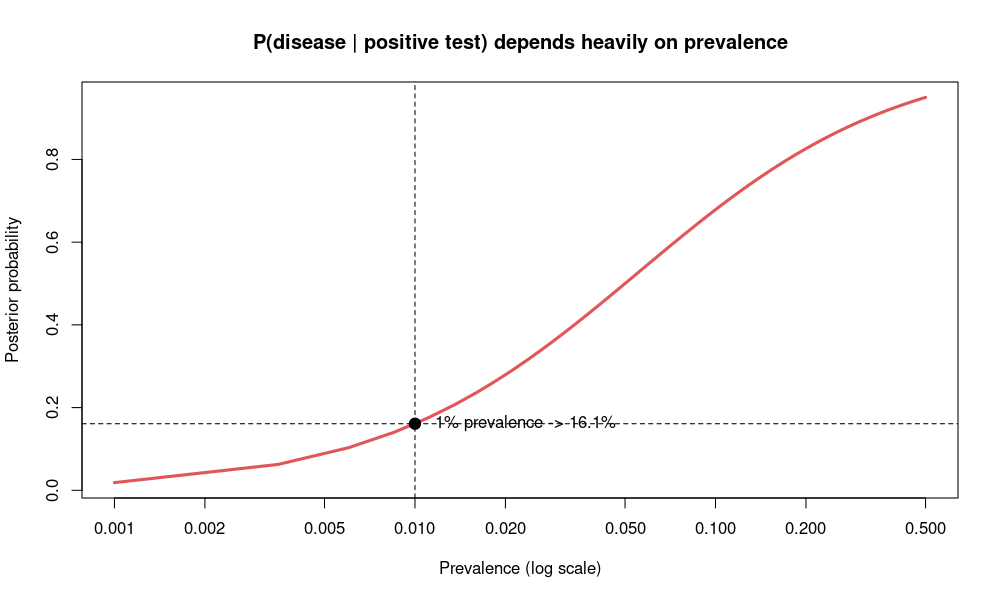

In [5]:
prevalence  <- 0.01
sensitivity <- 0.95   # P(+ | disease)
false_pos   <- 0.05   # P(+ | healthy)

p_positive <- sensitivity * prevalence + false_pos * (1 - prevalence)
p_disease_given_pos <- sensitivity * prevalence / p_positive
cat("P(test positive)          =", round(p_positive, 4), "\n")
cat("P(disease | test positive) =", round(p_disease_given_pos, 4), "\n\n")

# Verify by simulating 1,000,000 people
set.seed(7)
n <- 1e6
disease <- runif(n) < prevalence
positive <- ifelse(disease, runif(n) < sensitivity, runif(n) < false_pos)
cat("Simulated P(disease | positive) =", round(mean(disease[positive]), 4), "\n")

# How the answer depends on prevalence
prev_grid <- seq(0.001, 0.5, length.out = 200)
post <- sensitivity * prev_grid / (sensitivity * prev_grid + false_pos * (1 - prev_grid))
plot(prev_grid, post, type = "l", lwd = 3, col = "#E15759", log = "x",
     main = "P(disease | positive test) depends heavily on prevalence",
     xlab = "Prevalence (log scale)", ylab = "Posterior probability")
abline(v = prevalence, lty = 2); abline(h = p_disease_given_pos, lty = 2)
points(prevalence, p_disease_given_pos, pch = 19, cex = 1.5)
text(prevalence, p_disease_given_pos, sprintf("  1%% prevalence -> %.1f%%", 100 * p_disease_given_pos), pos = 4)

*Insight: Even with a "95% accurate" test, a positive result means only about a 16% chance of disease when the disease is rare — because healthy people vastly outnumber sick ones, and 5% of a huge number is still a lot of false positives. This is the **base-rate fallacy**.*

## 4. Random Variables, Expected Value and Variance

A **random variable** $X$ assigns a number to each outcome of an experiment (e.g. the value shown by a die). For a discrete random variable with probability mass function $p(x) = P(X = x)$:

$$
E[X] = \mu = \sum_x x \, p(x), \qquad
\text{Var}(X) = E\big[(X - \mu)^2\big] = E[X^2] - \big(E[X]\big)^2, \qquad
\text{SD}(X) = \sqrt{\text{Var}(X)}
$$

The **expected value** is the long-run average; the **variance** measures how far outcomes typically fall from it. Rules you will use constantly (for constants $a, b$):

| Rule | Formula |
|---|---|
| shift and scale | $E[aX + b] = aE[X] + b$, $\;\text{Var}(aX + b) = a^2\,\text{Var}(X)$ |
| sum of variables | $E[X + Y] = E[X] + E[Y]$ (always) |
| sum of **independent** variables | $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$ |
| mean of $n$ i.i.d. variables | $E[\bar{X}] = \mu$, $\;\text{Var}(\bar{X}) = \sigma^2 / n$ |

The last line is the seed of the Central Limit Theorem and of every standard error in this section (Lesson 05).

One fair die: E[X] = 3.5  Var(X) = 2.9167  (exact 35/12 = 2.9167 )


Shortcut     : E[X^2] - E[X]^2 = 2.9167 


Sum of two dice: E = 7  Var = 5.8333  (2 x 35/12 = 5.8333 )


Expected profit per game: -0.5 TL -> you lose 0.5 TL per game on average


Simulated average profit over 100,000 games: -0.502 TL


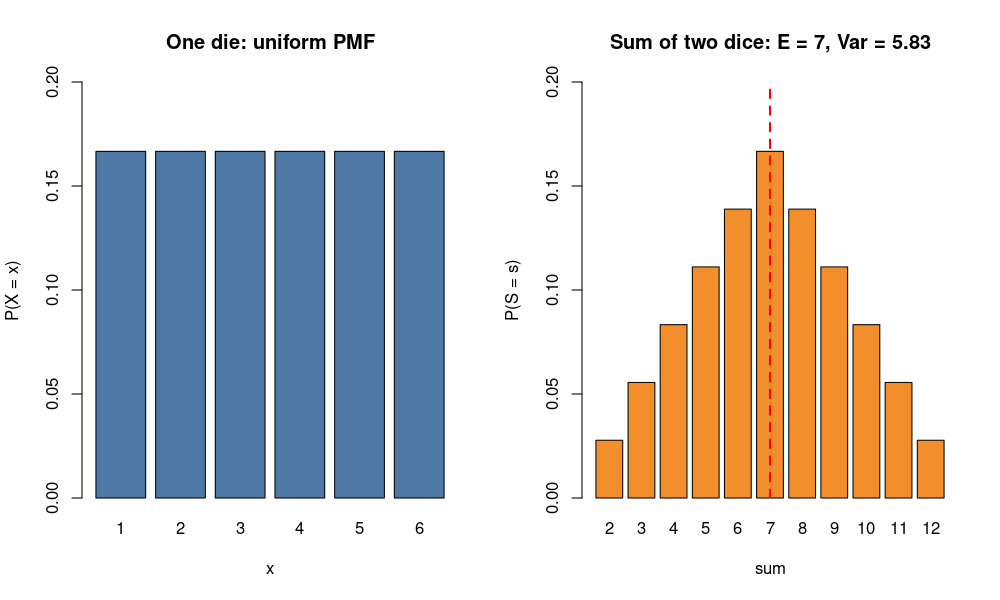

In [6]:
x  <- 1:6
px <- rep(1/6, 6)

EX   <- sum(x * px)
VarX <- sum((x - EX)^2 * px)
cat("One fair die: E[X] =", EX, " Var(X) =", round(VarX, 4), " (exact 35/12 =", round(35/12, 4), ")\n")
cat("Shortcut     : E[X^2] - E[X]^2 =", round(sum(x^2 * px) - EX^2, 4), "\n")

# Sum of two dice: E adds, and (because the dice are independent) Var adds too
two <- expand.grid(d1 = 1:6, d2 = 1:6)
s <- two$d1 + two$d2
cat("Sum of two dice: E =", mean(s), " Var =", round(mean((s - mean(s))^2), 4),
    " (2 x 35/12 =", round(2 * 35/12, 4), ")\n")

# Expected value of a game: pay 4 TL, win as many TL as the die shows
cat("Expected profit per game:", EX - 4, "TL -> you lose 0.5 TL per game on average\n")
set.seed(3)
profit <- sample(1:6, 1e5, replace = TRUE) - 4
cat("Simulated average profit over 100,000 games:", round(mean(profit), 3), "TL\n")

par(mfrow = c(1, 2))
barplot(px, names.arg = x, col = "#4E79A7", ylim = c(0, 0.2), main = "One die: uniform PMF",
        xlab = "x", ylab = "P(X = x)")
pmf2 <- table(s) / length(s)
bp <- barplot(pmf2, col = "#F28E2B", ylim = c(0, 0.2), main = "Sum of two dice: E = 7, Var = 5.83",
              xlab = "sum", ylab = "P(S = s)")
abline(v = bp[names(pmf2) == "7"], col = "red", lwd = 2, lty = 2)

*Insight: Adding two dice does not give a flat distribution from 2 to 12 — the middle values have many more ways to happen. This "piling up in the middle" when you add random variables is exactly what the Central Limit Theorem formalises.*

## 5. Law of Large Numbers

Probability is a long-run frequency: as the number of trials grows, the observed proportion converges to the true probability.

Proportion after 10 rolls: 0.6 | after 5000 rolls: 0.5072 


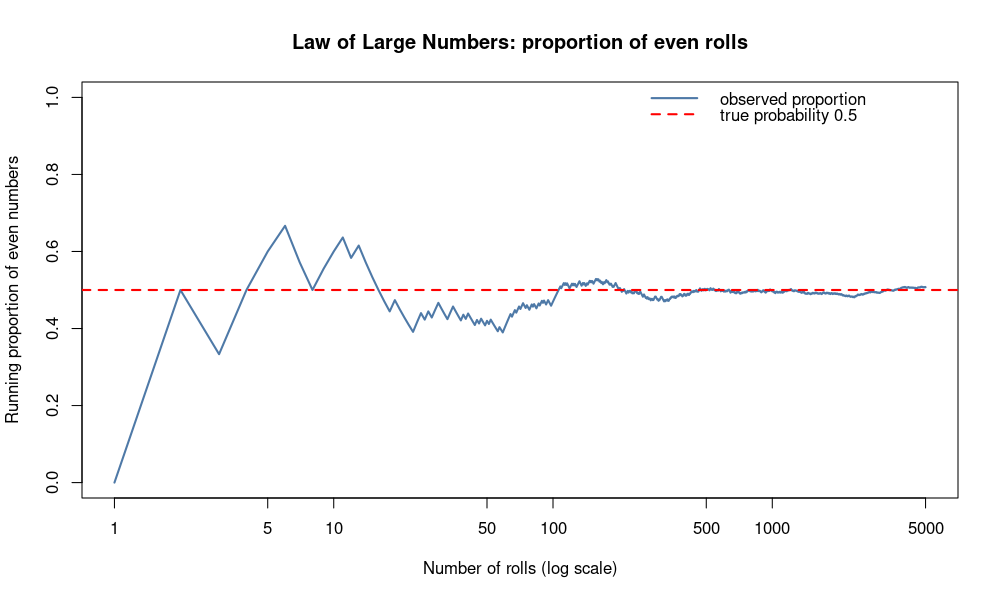

In [7]:
set.seed(123)
rolls <- sample(1:6, 5000, replace = TRUE)
running <- cumsum(rolls %% 2 == 0) / seq_along(rolls)

plot(running, type = "l", col = "#4E79A7", lwd = 2, log = "x", ylim = c(0, 1),
     main = "Law of Large Numbers: proportion of even rolls", xlab = "Number of rolls (log scale)",
     ylab = "Running proportion of even numbers")
abline(h = 0.5, col = "red", lty = 2, lwd = 2)
legend("topright", c("observed proportion", "true probability 0.5"), col = c("#4E79A7", "red"),
       lty = c(1, 2), lwd = 2, bty = "n")
cat("Proportion after 10 rolls:", running[10], "| after 5000 rolls:", round(running[5000], 4), "\n")

## Real-World Use Case or Analogy

- **Die roll**: a simple chance experiment.
- **Conditional probability**: the chance of rain *given* that the sky is cloudy is higher than the chance of rain on a random day.
- **Bayes' theorem**: a spam filter. The word "lottery" is much more likely in spam, so seeing it updates the probability that an email is spam — but how much depends on how common spam is to begin with (the base rate).
- **Law of large numbers**: a casino can lose on any single bet, but over millions of bets its profit is almost perfectly predictable.